# 基于 Adam 的卷积神经网络训练：数值稳定性与超参数敏感性分析

## 概述

本报告以 Adam 优化算法训练小型卷积神经网络（CNN）为研究对象，将数值分析中的迭代法稳定性、条件数与收敛性分析，与人工智能中的图像分类训练过程结合起来。报告围绕两个问题展开：一是在病态二次型上检验 Adam 的尺度不变性，并以 GD 的稳定域与条件数作为背景参照；二是在真实 CNN 训练中考察 Adam 的学习率、$\beta_1$、$\beta_2$、$\epsilon$ 敏感性，并与动量 SGD 对照。本 Notebook 需在 conda 虚拟环境 jup 中运行，需安装 numpy、pandas、matplotlib、scikit-learn、torch 等包。

## 1. 问题背景

### 1.1 人工智能中的训练问题

卷积神经网络（CNN）是图像分类、目标检测和医学影像分析等任务的核心模型之一。CNN 的训练本质上是一个高维非凸优化问题：给定训练集 $\{(x_i,y_i)\}_{i=1}^{N}$，网络参数为 $\theta$，经验风险为

$$
L(\theta)=\frac{1}{N}\sum_{i=1}^{N}\ell\bigl(f_\theta(x_i),y_i\bigr),
$$

其中 $\ell$ 为交叉熵损失，$f_\theta$ 为网络输出。训练通过反向传播计算 $\nabla_\theta L$，再由优化算法迭代更新 $\theta$。在实际训练中，学习率过大可能导致损失振荡或发散，学习率过小则收敛缓慢；不同参数的梯度尺度差异很大，统一步长难以同时适配所有坐标。这些现象都可以从数值分析的角度加以解释。

### 1.2 数值分析视角

从数值分析看，训练算法是一个求解非线性方程 $\nabla L(\theta)=0$ 的迭代法。梯度下降可视为梯度流

$$
\dot\theta=-\nabla L(\theta)
$$

的显式 Euler 离散：

$$
\theta_{k+1}=\theta_k-\alpha\nabla L(\theta_k).
$$

因此，步长 $\alpha$ 的选取、迭代矩阵的谱半径、问题的条件数等概念，直接决定了训练是否稳定、收敛多快。

Adam（Adaptive Moment Estimation）是深度学习中应用极广的自适应优化算法。针对 CNN 网络层间梯度尺度差异大的固有特点，在 GD 的基础上引入梯度的一阶、二阶指数滑动平均，为每一个参数维度独立构造自适应学习步长，无需精细调参也能适配不同量级的梯度，缓解固定学习率带来的训练不稳定、收敛慢的问题，大幅降低卷积网络的训练调参成本，因此被广泛应用于 CNN、Transformer 等深度模型的训练任务中。

### 1.3 研究问题

本报告围绕两个问题展开。

**问题一**：在可解析分析的病态二次型问题上，探究 Adam 算法的尺度不变特性；当目标函数整体缩放时，Adam 算法的迭代轨迹是否具备不变性。

**问题二**：在真实 CNN 训练中，Adam 的学习率、$\beta_1$、$\beta_2$、$\epsilon$ 对模型收敛速度、迭代数值稳定性以及最终泛化性能产生何种影响。对比 Adam 与动量 SGD 算法在 CNN 训练上的行为差异。

## 2. 核心算法

### 2.1 一阶优化算法
一阶优化算法依靠损失函数对模型参数的梯度迭代更新参数，是深度学习与数值优化问题中最常用的求解手段。

设 $g_t=\nabla_\theta L(\theta_t)$，学习率为 $\alpha$。梯度下降（GD）为

$$
\theta_{t+1}=\theta_t-\alpha g_t .
$$

动量法引入速度项

$$
v_{t+1}=\beta v_t+g_t,\qquad \theta_{t+1}=\theta_t-\alpha v_{t+1},
$$

其中 $\beta=0.9$。

Adam 算法在动量法一阶平滑的基础上，额外维护梯度二阶指数滑动平均，利用梯度幅值自适应调整各参数的有效步长，这也是 Adam 具备潜在尺度不变特性的核心来源。

$$
m_t=\beta_1m_{t-1}+(1-\beta_1)g_t,\qquad
v_t=\beta_2v_{t-1}+(1-\beta_2)g_t^2,
$$

$$
\hat m_t=\frac{m_t}{1-\beta_1^t},\qquad
\hat v_t=\frac{v_t}{1-\beta_2^t},\qquad
\theta_{t+1}=\theta_t-\alpha\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}.
$$

默认参数为 $\beta_1=0.9$、$\beta_2=0.999$、$\epsilon=10^{-8}$。对二次型 $f(\theta)=\tfrac12\theta^{T}A\theta$，梯度为 $A\theta$，上述迭代可直接写出，便于解析分析。

### 2.2 CNN 与交叉熵损失
为在真实非凸深度学习场景下测试优化器的实际表现，本文搭建轻量化卷积神经网络，基于手写数字分类任务开展实验；网络训练采用交叉熵损失函数，通过反向传播计算参数梯度，供 Adam 与动量 SGD 优化器迭代更新权重。
网络输入为 $8\times8$ 灰度图像，依次经过

$$
\text{Conv}(1\to8,3\times3)\to\text{ReLU}\to\text{MaxPool}(2)
\to\text{Conv}(8\to16,3\times3)\to\text{ReLU}
\to\text{FC}(256\to32)\to\text{ReLU}\to\text{FC}(32\to10),
$$

共 9802 个参数。数据为 scikit-learn 自带的 Digits（$8\times8$ 灰度手写数字，1797 个样本），按 $70\%/15\%/15\%$ 划分为训练、验证、测试集。损失为交叉熵

$$
L(\theta)=-\frac{1}{N}\sum_{i=1}^{N}\log\frac{\exp(z_{i,y_i})}{\sum_{j=1}^{10}\exp(z_{i,j})},
$$

其中 $z_i$ 为网络对样本 $i$ 的输出，梯度由反向传播计算。

## 3. 理论分析

### 3.1 梯度流、显式 Euler 与步长稳定域

在讨论 Adam 之前，先用二次型回顾一阶方法的经典稳定性结论，作为后续分析的参照。连续时间下，梯度下降是梯度流 $\dot\theta=-\nabla L(\theta)$；显式 Euler 离散给出

$$
\theta_{k+1}=\theta_k-\alpha\nabla L(\theta_k).
$$

对二次型 $f(\theta)=\tfrac12\theta^{T}A\theta$，梯度为 $A\theta$，误差 $e_k=\theta_k-\theta^*$ 满足

$$
e_{k+1}=(I-\alpha A)e_k .
$$

设 $A$ 的特征值为 $0<\lambda_1\le\cdots\le\lambda_d=L$，则第 $i$ 个特征方向按 $(1-\alpha\lambda_i)^k$ 衰减。迭代收敛当且仅当

$$
|1-\alpha\lambda_i|<1\quad\forall i
\iff 0<\alpha<\frac{2}{L}.
$$

这就是步长稳定域。收敛因子为

$$
\rho(\alpha)=\max_i|1-\alpha\lambda_i|,
$$

最优步长 $\alpha^*=2/(\lambda_1+L)$，对应 $\rho^*=(\kappa-1)/(\kappa+1)$，其中条件数 $\kappa=L/\lambda_1$。$\kappa$ 越大，收敛因子越接近 1，达到给定精度所需迭代数约按 $\kappa$ 增长。上述结论能够解释CNN训练中学习率过大引发发散、病态优化问题收敛缓慢等现象。

### 3.2 Adam 的偏差校正与尺度不变性

问题一的核心是 Adam 的尺度不变性。$m_t$ 是梯度的指数滑动平均，其期望为 $(1-\beta_1^t)\mathbb E[g]$，因此除以 $1-\beta_1^t$ 得到无偏估计；$v_t$ 同理。偏差校正使训练初期的更新幅度不被零初始化压低。

尺度不变性：若目标函数变为 $cL$，则 $g_t\to cg_t$，$m_t\to cm_t$，$v_t\to c^2v_t$，于是

$$
\frac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}\longrightarrow
\frac{c\hat m_t}{c\sqrt{\hat v_t}+\epsilon}.
$$

当 $c\sqrt{\hat v_t}\gg\epsilon$ 时，该比值近似不变，故 Adam 对目标整体缩放近似不变。GD 则不同：梯度放大 $c$ 倍等价于步长放大 $c$ 倍，可能越过稳定阈值 $2/L$ 而发散。$\epsilon$ 是尺度不变性的破坏项；$\epsilon$ 越大，自适应步长被压得越低。

另一方面，Adam 的归一化更新使每个坐标的更新幅度约为 $\alpha$，但这不意味着无条件稳定：$\alpha$ 过大时参数仍会剧烈振荡甚至发散。

### 3.3 超参数作用与实验假设
本节基于 Adam 迭代规则，定性分析各超参数对优化过程的潜在影响，并对 Adam 与动量 SGD 的训练行为提出假设，后续将在 CNN 手写数字分类实验中验证。
- 学习率 $\alpha$：过小收敛慢，过大振荡或发散。假设 $\alpha=10^{-2}$ 最优，$5\times10^{-2}$ 不稳定，$10^{-1}$ 失效。
- 一阶矩系数 $\beta_1$：越大，动量记忆越长、对梯度变化的响应越慢。假设 $\beta_1=0.99$ 明显变差，$0.5$ 影响较小。
- 二阶矩系数 $\beta_2$：越小，$\hat v_t$ 噪声越大；越大，对梯度尺度的适应越慢。假设 $\beta_2=0.9$ 变差，$0.9999$ 接近默认。
- 稳定项 $\epsilon$：越大，有效步长越小。假设 $\epsilon=10^{-3}$ 损害精度，$10^{-5}$ 与默认接近。
- 与动量 SGD 相比，默认 Adam 初期收敛更快，但最终泛化未必更好；合适学习率下的 Adam 可以超过 SGD。

## 4. 编程实践

### 4.1 实验环境与数据模型

实验基于 Python 与 PyTorch 实现，设置随机种子、训练轮数、批大小、输出目录与统一配色。数据按 $70\%/15\%/15\%$ 划分，划分种子固定为 2026；每个 CNN 配置使用 3 个随机种子 $\{2026,2027,2028\}$ 重复，并同时固定参数初始化与训练批顺序。评价指标为交叉熵损失与分类准确率。

In [1]:
from __future__ import annotations
#导入库
import random
import warnings
from pathlib import Path
from IPython.display import Image, display
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
#数据分析相关库
import numpy as np
import pandas as pd
#深度学习相关库
import torch
import torch.nn as nn
# sklearn数据集与数据划分工具
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

# 绘图样式配置
SPLIT_SEED = 2026               # 数据划分种子
SEEDS = [2026, 2027, 2028]      # 每个配置重复 3 次
EPOCHS = 18                     # 训练轮数
BATCH_SIZE = 64
DEVICE = torch.device("cpu")

ROOT = Path.cwd().parent if Path.cwd().name == "代码" else Path.cwd()
OUT = ROOT / "实验结果"
FIG_DIR = OUT / "图表" / "报告实验"
DATA_DIR = OUT / "数据表" / "报告实验"
FIG_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)

# 类别色按固定顺序使用；文字使用墨色，不使用系列色
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
          "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"

plt.rcParams.update({
    "figure.dpi": 150, "savefig.dpi": 200, "font.size": 10,
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "axes.unicode_minus": False,
    "lines.linewidth": 1.6,
})


def savefig(fig, name: str) -> None:
    fig.savefig(FIG_DIR / name, bbox_inches="tight", facecolor=SURFACE)
    plt.close(fig)


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


# 数据集加载、预处理、划分与DataLoader构建
digits = load_digits()
X = (digits.images / 16.0).astype(np.float32)
y = digits.target.astype(np.int64)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=SPLIT_SEED, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=SPLIT_SEED, stratify=y_temp
)


def make_loader(images, labels, shuffle: bool, seed: int | None = None) -> DataLoader:
    dataset = TensorDataset(
        torch.from_numpy(images).unsqueeze(1), torch.from_numpy(labels)
    )
    generator = torch.Generator().manual_seed(seed) if seed is not None else None
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle, generator=generator)


val_loader = make_loader(X_val, y_val, shuffle=False)
test_loader = make_loader(X_test, y_test, shuffle=False)

#轻量化卷积神经网络
class SmallCNN(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(8, 16, 3, padding=1), nn.ReLU(),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(16 * 4 * 4, 32), nn.ReLU(), nn.Linear(32, 10)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.classifier(self.features(x))


def evaluate(model: nn.Module, loader: DataLoader, criterion: nn.Module) -> tuple[float, float]:
    model.eval()
    loss_sum = correct = total = 0
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
            logits = model(x_batch)
            loss_sum += criterion(logits, y_batch).item() * y_batch.size(0)
            correct += (logits.argmax(dim=1) == y_batch).sum().item()
            total += y_batch.size(0)
    return loss_sum / total, correct / total

### 4.2 二次型实验

取 $d=20$，$A=\operatorname{diag}(\lambda_1,\dots,\lambda_{20})$，$\lambda_i$ 在 $[1,100]$ 上对数等距分布，初值 $\theta_0=\mathbf{1}$，迭代 $T=1000$ 步。比较五组 GD 步长（$10^{-3}$、$10^{-2}$、$1.9\times10^{-2}$、$2.1\times10^{-2}$、$5\times10^{-2}$）、动量法与 Adam；并把目标函数整体放大 $10^{3}$ 倍，以检验 Adam 的尺度不变性。记录归一化目标 $f(\theta_t)/f(\theta_0)$，收敛判据取 $10^{-6}$。

In [3]:
#二次型优化实验函数
def quadratic_experiment() -> pd.DataFrame:
    d, T = 20, 1000
    lam = np.logspace(0.0, 2.0, d)          # 条件数 κ(A) = 100
    theta0 = np.ones(d)
    f0 = 0.5 * np.sum(lam * theta0**2)

    def run(kind: str, alpha: float, scale: float = 1.0) -> np.ndarray:
        """kind: gd / momentum / adam；scale 同时放大目标函数与梯度。"""
        theta = theta0.copy()
        mom = m = v = np.zeros(d)
        hist = np.empty(T)
        with np.errstate(over="ignore", invalid="ignore"):
            for t in range(1, T + 1):
                hist[t - 1] = 0.5 * np.sum(lam * theta**2) / f0   # 归一化目标
                g = scale * lam * theta
                if kind == "gd":
                    theta = theta - alpha * g
                elif kind == "momentum":
                    mom = 0.9 * mom + g
                    theta = theta - alpha * mom
                else:
                    m = 0.9 * m + 0.1 * g
                    v = 0.999 * v + 0.001 * g * g
                    m_hat = m / (1.0 - 0.9**t)
                    v_hat = v / (1.0 - 0.999**t)
                    theta = theta - alpha * m_hat / (np.sqrt(v_hat) + 1e-8)
                if not np.all(np.isfinite(theta)):
                    hist[t:] = np.nan
                    break
        return hist
# 论文设置的5组GD步长，覆盖稳定域内、临近上界、超出稳定域的情况
    alphas = [1e-3, 1e-2, 1.9e-2, 2.1e-2, 5e-2]
    gd = {a: run("gd", a) for a in alphas}
    momentum = run("momentum", 1e-2)
    adam = run("adam", 1e-2)
    adam_scaled = run("adam", 1e-2, scale=1e3)
    gd_scaled = run("gd", 1e-2, scale=1e3)

    def ready(h: np.ndarray) -> np.ndarray:
        return np.where(np.isfinite(h), np.clip(h, 1e-30, 1e15), np.nan)

    # ---------- 图 1：尺度不变性 / 算法对比 / 步长稳定域 ----------
    fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.9))

    # (a) 尺度不变性：Adam 在目标放大后轨迹重合，GD 发散
    axes[0].plot(ready(adam), color=COLORS[0], label="Adam, $f$")
    axes[0].plot(ready(adam_scaled), color=COLORS[0], ls="--", label="Adam, $10^3 f$")
    axes[0].plot(ready(gd_scaled), color=COLORS[3], ls=":", label="GD, $10^3 f$ (diverge)")
    axes[0].set(title="(a) Adam: scale invariance", xlabel="Iteration $t$",
                ylabel="$f(\\theta_t)/f(\\theta_0)$", yscale="log")
    axes[0].legend(fontsize=8, loc="lower left")

    # (b) GD / 动量 / Adam 的收敛速度
    for i, (name, h) in enumerate([("GD", gd[1e-2]), ("Momentum", momentum), ("Adam", adam)]):
        axes[1].plot(ready(h), color=COLORS[i], label=name)
    axes[1].axhline(1e-6, color=MUTED, lw=1, ls=":")
    axes[1].set(title="(b) GD vs Momentum vs Adam", xlabel="Iteration $t$",
                ylabel="$f(\\theta_t)/f(\\theta_0)$", yscale="log")
    axes[1].legend(fontsize=8, loc="lower left")

    # (c) 背景：GD 的步长稳定域
    labels = ["$\\alpha=10^{-3}$", "$\\alpha=10^{-2}$",
              "$\\alpha=1.9\\times10^{-2}$", "$\\alpha=2.1\\times10^{-2}$ (diverge)",
              "$\\alpha=5\\times10^{-2}$ (diverge)"]
    for i, (a, label) in enumerate(zip(alphas, labels)):
        axes[2].plot(ready(gd[a]), color=COLORS[i], label=label)
    axes[2].axhline(1e-6, color=MUTED, lw=1, ls=":")
    axes[2].set(title="(c) GD: step-size stability (background)", xlabel="Iteration $t$",
                ylabel="$f(\\theta_t)/f(\\theta_0)$", yscale="log")
    axes[2].legend(fontsize=8, loc="lower left")

    fig.tight_layout()
    savefig(fig, "二次型收敛性与稳定性.png")

    # ---------- 表 1：收敛所需迭代数 ----------
    def diverged(h: np.ndarray) -> bool:
        return bool(np.any(~np.isfinite(h)) or np.nanmax(h) > 1e6)

    def iterations(h: np.ndarray, tol: float = 1e-6):
        idx = np.where(np.isfinite(h) & (h <= tol))[0]
        return int(idx[0] + 1) if idx.size else "—"

    def final_ratio(h: np.ndarray):
        return "发散" if diverged(h) else f"{h[-1]:.3e}"

    alpha_tex = {1e-3: "$10^{-3}$", 1e-2: "$10^{-2}$",
                 1.9e-2: "$1.9\\times10^{-2}$", 2.1e-2: "$2.1\\times10^{-2}$",
                 5e-2: "$5\\times10^{-2}$"}
    rows = [
        {"方法": "GD", "设置": f"$\\alpha$={alpha_tex[a]}",
         "是否发散": "是" if diverged(gd[a]) else "否",
         "达到 $10^{-6}$ 的迭代数": iterations(gd[a]),
         "最终 $f/f_0$": final_ratio(gd[a])}
        for a in alphas
    ]
    for name, h in [("Momentum", momentum), ("Adam", adam)]:
        rows.append({"方法": name, "设置": "$\\alpha=10^{-2}$",
                     "是否发散": "是" if diverged(h) else "否",
                     "达到 $10^{-6}$ 的迭代数": iterations(h),
                     "最终 $f/f_0$": final_ratio(h)})
    for name, h in [("Adam", adam_scaled), ("GD", gd_scaled)]:
        rows.append({"方法": name, "设置": "$\\alpha=10^{-2},\\ 10^3f$",
                     "是否发散": "是" if diverged(h) else "否",
                     "达到 $10^{-6}$ 的迭代数": iterations(h),
                     "最终 $f/f_0$": final_ratio(h)})

    table = pd.DataFrame(rows)
    table.to_csv(DATA_DIR / "二次型实验汇总.csv", index=False, encoding="utf-8-sig")
    print("二次型实验完成")
    return table

### 4.3 CNN 超参数扫描

实验采用控制变量法：12 组配置（动量 SGD 基线、Adam 默认、4 组学习率、2 组 $\beta_1$、2 组 $\beta_2$、2 组 $\epsilon$），每组用 3 个随机种子重复。训练 18 个 epoch，批大小 64，记录训练/验证损失、验证准确率、测试准确率与梯度范数，并检测损失、梯度或参数是否出现非有限值。最终报告均值 ± 标准差。

In [5]:
# 构造Adam优化器的工厂函数
def adam(lr: float = 1e-3, beta1: float = 0.9, beta2: float = 0.999, eps: float = 1e-8):
    return lambda params: torch.optim.Adam(params, lr=lr, betas=(beta1, beta2), eps=eps)
# 封装单组实验配置的辅助函数
def cfg(key: str, label: str, group: str, factory) -> dict:
    return {"key": key, "label": label, "group": group, "factory": factory}
# 实验配置总表，对应CNN超参数扫描，一共12组
CONFIGS = [
    cfg("sgd", "SGD (lr=0.02, m=0.9)", "baseline",
        lambda p: torch.optim.SGD(p, lr=0.02, momentum=0.9)),
    cfg("adam", "Adam (default)", "baseline", adam()),
    cfg("adam_lr1e-4", "Adam (lr=1e-4)", "lr", adam(lr=1e-4)),
    cfg("adam_lr1e-2", "Adam (lr=1e-2)", "lr", adam(lr=1e-2)),
    cfg("adam_lr5e-2", "Adam (lr=5e-2)", "lr", adam(lr=5e-2)),
    cfg("adam_lr1e-1", "Adam (lr=1e-1)", "lr", adam(lr=1e-1)),
    cfg("adam_b1_0.5", "Adam (beta1=0.5)", "beta1", adam(beta1=0.5)),
    cfg("adam_b1_0.99", "Adam (beta1=0.99)", "beta1", adam(beta1=0.99)),
    cfg("adam_b2_0.9", "Adam (beta2=0.9)", "beta2", adam(beta2=0.9)),
    cfg("adam_b2_0.9999", "Adam (beta2=0.9999)", "beta2", adam(beta2=0.9999)),
    cfg("adam_eps1e-5", "Adam (eps=1e-5)", "eps", adam(eps=1e-5)),
    cfg("adam_eps1e-3", "Adam (eps=1e-3)", "eps", adam(eps=1e-3)),
]
# 单次训练任务：一组优化器配置 + 一个随机种子，完成CNN完整训练
def train_one(config: dict, seed: int) -> dict:
    set_seed(seed)
    model = SmallCNN().to(DEVICE)
    train_loader = make_loader(X_train, y_train, shuffle=True, seed=seed)
    criterion = nn.CrossEntropyLoss()
    optimizer = config["factory"](model.parameters())
    history = {k: np.full(EPOCHS, np.nan)
               for k in ("train_loss", "val_loss", "val_acc", "grad_norm")}
    diverged = False
# 遍历每一个训练轮次epoch
    for epoch in range(EPOCHS):
        model.train()
        loss_sum = samples = grad_sum = batches = 0
        for x_batch, y_batch in train_loader:
            x_batch, y_batch = x_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(x_batch), y_batch)
            if not torch.isfinite(loss):
                diverged = True
                break
            loss.backward()
            grad_sq = sum(p.grad.detach().pow(2).sum().item()
                          for p in model.parameters() if p.grad is not None)
            if not np.isfinite(grad_sq):
                diverged = True
                break
            grad_sum += grad_sq**0.5
            batches += 1
            optimizer.step()
            if not all(torch.isfinite(p).all() for p in model.parameters()):
                diverged = True
                break
            loss_sum += loss.item() * y_batch.size(0)
            samples += y_batch.size(0)
        if diverged:# 如果已经发散，直接终止epoch循环
            break
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        history["train_loss"][epoch] = loss_sum / samples
        history["val_loss"][epoch] = val_loss
        history["val_acc"][epoch] = val_acc
        history["grad_norm"][epoch] = grad_sum / batches
# 如果中途发散，测试指标赋值nan；否则在测试集评估
    test_loss, test_acc = (np.nan, np.nan) if diverged else evaluate(model, test_loader, criterion)
    return {
        "config": config["key"], "label": config["label"], "group": config["group"],
        "seed": seed, "diverged": diverged, "test_loss": test_loss, "test_acc": test_acc,
        "final_val_loss": history["val_loss"][-1],
        "final_val_acc": history["val_acc"][-1],
        "final_grad_norm": history["grad_norm"][-1],
        "history": history,
    }

# 绘图y轴名称映射字典
YLABEL = {
    "train_loss": "Training loss",
    "val_loss": "Validation loss",
    "val_acc": "Validation accuracy",
    "grad_norm": "Mean gradient norm",
}

# 在单个子图上绘制多条曲线：均值+标准差填充区间
def plot_curves(ax, keys: list[str], metric: str, title: str, show_legend: bool = True) -> None:
    for i, key in enumerate(keys):
        runs = [r for r in all_runs if r["config"] == key]
        stacked = np.vstack([r["history"][metric] for r in runs])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", RuntimeWarning)
            mean, std = np.nanmean(stacked, axis=0), np.nanstd(stacked, axis=0)
        low, high = mean - std, mean + std
        if metric == "val_acc":            # 准确率及其区间不超出 [0, 1]
            mean, low, high = (np.clip(v, 0.0, 1.0) for v in (mean, low, high))
        epochs = np.arange(1, EPOCHS + 1)
        ax.plot(epochs, mean, marker="o", ms=3, color=COLORS[i], label=runs[0]["label"])
        ax.fill_between(epochs, low, high, color=COLORS[i], alpha=0.12, lw=0)
    ax.set(xlabel="Epoch", ylabel=YLABEL[metric], title=title)
    if show_legend:
        ax.legend(fontsize=8)
# 批量生成一行多子图的对比图
def plot_panels(key_sets, metrics, titles, filename: str, shared_legend: bool = False) -> None:
    fig, axes = plt.subplots(1, len(metrics), figsize=(4.4 * len(metrics), 3.9), squeeze=False)
    for ax, keys, metric, title in zip(axes[0], key_sets, metrics, titles):
        plot_curves(ax, keys, metric, title, show_legend=not shared_legend)
    if shared_legend:
        handles, labels = axes[0][0].get_legend_handles_labels()
        fig.tight_layout(rect=(0, 0.08, 1, 1))
        fig.legend(handles, labels, loc="lower center", ncol=len(labels),
                   fontsize=8, frameon=False)
    else:
        fig.tight_layout()
    savefig(fig, filename)
# CNN超参数扫描主实验函数
def cnn_experiments() -> pd.DataFrame:
    global all_runs
    all_runs = [train_one(config, seed) for config in CONFIGS for seed in SEEDS]
    for r in all_runs:
        status = "DIVERGED" if r["diverged"] else f"test_acc={r['test_acc']:.4f}"
        print(f"{r['label']:<24} seed={r['seed']} {status}")

    history_rows = [
        {
            "config": r["config"], "label": r["label"], "seed": r["seed"], "epoch": e + 1,
            **{k: r["history"][k][e] for k in ("train_loss", "val_loss", "val_acc", "grad_norm")},
        }
        for r in all_runs for e in range(EPOCHS)
    ]
    pd.DataFrame(history_rows).to_csv(
        DATA_DIR / "CNN训练历史.csv", index=False, encoding="utf-8-sig"
    )
# 辅助函数：计算一组有效数值的均值和标准差，自动过滤nan
    def mean_std(values):
        values = np.asarray(values, dtype=float)
        values = values[np.isfinite(values)]
        return (float(values.mean()), float(values.std())) if values.size else (np.nan, np.nan)

    def fmt(pair):
        return f"{pair[0]:.4f}±{pair[1]:.4f}"

    rows = []# 遍历所有配置，汇总多次种子的统计结果
    for config in CONFIGS:
        runs = [r for r in all_runs if r["config"] == config["key"]]
        finite = [r for r in runs if not r["diverged"]]
        rows.append({
            "组别": config["group"],
            "配置": config["label"],
            "有效种子数": len(finite),
            "测试损失": fmt(mean_std([r["test_loss"] for r in finite])),
            "测试准确率": fmt(mean_std([r["test_acc"] for r in finite])),
            "验证损失": fmt(mean_std([r["final_val_loss"] for r in finite])),
            "验证准确率": fmt(mean_std([r["final_val_acc"] for r in finite])),
            "梯度范数": fmt(mean_std([r["final_grad_norm"] for r in finite])),
        })
    table = pd.DataFrame(rows)
    table.to_csv(DATA_DIR / "CNN实验汇总.csv", index=False, encoding="utf-8-sig")
    print("\nCNN 实验汇总（均值±标准差，3 个随机种子）：")
    print(table.to_string(index=False))
# 绘图1：Adam基线与SGD基线对比
    plot_panels(
        [["sgd", "adam"]] * 3,
        ["val_loss", "val_acc", "grad_norm"],
        ["(a) Validation loss", "(b) Validation accuracy", "(c) Gradient norm"],
        "Adam与SGD基线对比.png",
        shared_legend=True,
    )
 # 绘图2：学习率敏感性扫描
    plot_panels(
        [["adam_lr1e-4", "adam", "adam_lr1e-2", "adam_lr5e-2", "adam_lr1e-1"]] * 2,
        ["val_loss", "val_acc"],
        ["(a) Validation loss", "(b) Validation accuracy"],
        "学习率敏感性.png",
        shared_legend=True,
    )
# 绘图3：beta1、beta2矩系数敏感性
    plot_panels(
        [["adam_b1_0.5", "adam", "adam_b1_0.99"],
         ["adam_b2_0.9", "adam", "adam_b2_0.9999"]],
        ["val_loss", "val_loss"],
        ["(a) $\\beta_1$ sweep", "(b) $\\beta_2$ sweep"],
        "矩估计系数敏感性.png",
    )
    # 绘图4：eps稳定项敏感性
    plot_panels(
        [["adam", "adam_eps1e-5", "adam_eps1e-3"]],
        ["val_loss"],
        ["$\\epsilon$ sweep"],
        "稳定项敏感性.png",
    )
    return table

## 5. 数值结果

### 5.1 二次型实验：Adam 的尺度不变性

把目标函数整体放大 $10^{3}$ 倍后，Adam 的归一化收敛曲线与原始目标重合，均在 270 次迭代达到 $10^{-6}$；同样放大下 GD 直接发散。这说明 Adam 的更新对梯度整体尺度近似不变：$m_t$ 与梯度同比例放大，$v_t$ 按平方比例放大，$\hat m_t/\sqrt{\hat v_t}$ 基本不变；$\epsilon$ 是破坏严格不变性的项。

作为背景，二次型还给出了两个经典现象：GD 的稳定域与 $0<\alpha<2/L$ 一致（$\alpha=1.9\times10^{-2}$ 时 206 次收敛，$2.1\times10^{-2}$ 时发散）；条件数 $\kappa=100$ 使 GD 收敛较慢（391 次），动量法 125 次，Adam 270 次。上述基础规律为后续 CNN 上的 Adam 超参数敏感性实验提供理论参照，也说明理想二次场景下得到的尺度不变性，有待在非线性神经网络中进一步检验。

二次型实验完成


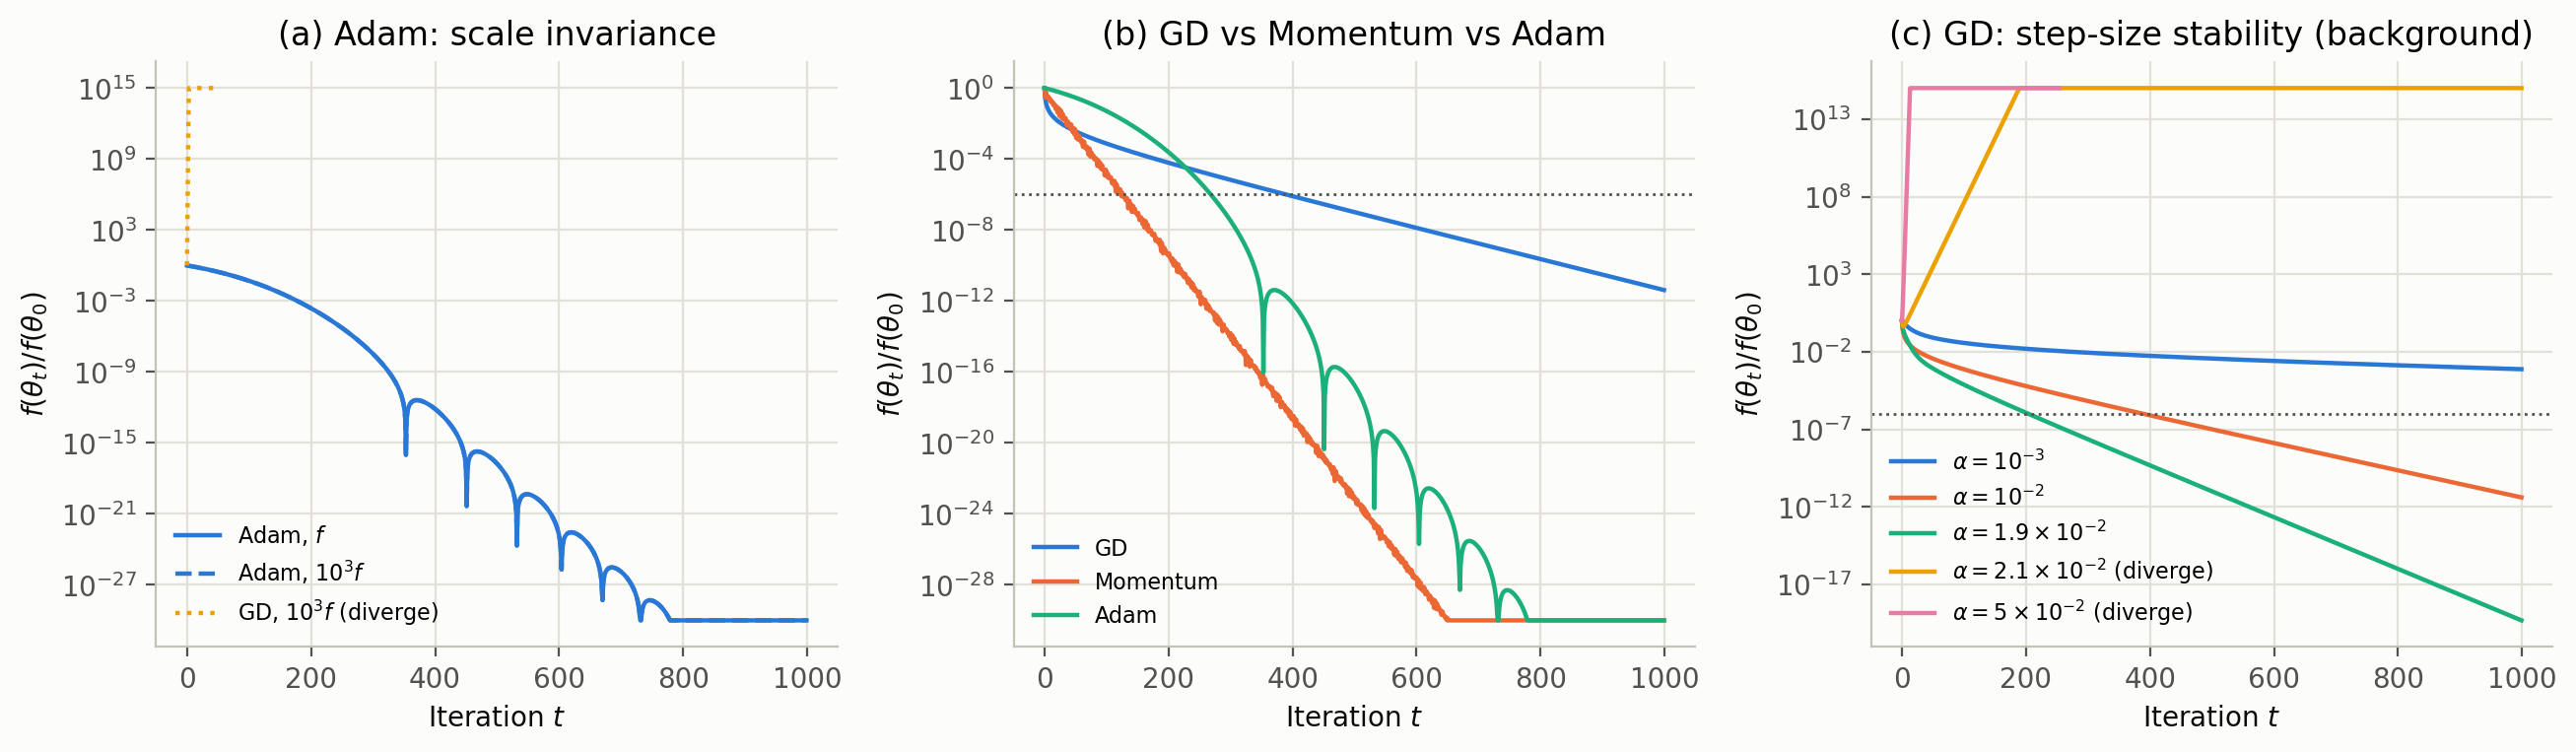

,方法,设置,是否发散,达到 $10^{-6}$ 的迭代数,最终 $f/f_0$
0,GD,$\alpha$=$10^{-3}$,否,—,7.589e-04
1,GD,$\alpha$=$10^{-2}$,否,391,4.146e-12
2,GD,$\alpha$=$1.9\times10^{-2}$,否,206,4.909e-20
3,GD,$\alpha$=$2.1\times10^{-2}$,是,—,发散
4,GD,$\alpha$=$5\times10^{-2}$,是,—,发散
5,Momentum,$\alpha=10^{-2}$,否,125,9.048e-47
6,Adam,$\alpha=10^{-2}$,否,270,6.999e-43
7,Adam,"$\alpha=10^{-2},\ 10^3f$",否,270,6.999e-43
8,GD,"$\alpha=10^{-2},\ 10^3f$",是,—,发散


In [4]:
quadratic_table = quadratic_experiment()
display(Image(filename=str(FIG_DIR / "二次型收敛性与稳定性.png")))
display(quadratic_table)

### 5.2 CNN 实验

基线：动量 SGD 的测试损失与准确率为 $0.1130\pm0.0135$、$0.9630\pm0.0060$；默认 Adam 为 $0.1762\pm0.0129$、$0.9481\pm0.0030$。Adam 在前几个 epoch 下降更快，但最终动量 SGD 的测试损失更低、准确率略高。

超参数敏感性的主要结果：

- 学习率是最敏感的超参数：$\alpha=10^{-2}$ 取得最佳测试准确率 $0.9840\pm0.0017$；$\alpha=5\times10^{-2}$ 出现高方差（$0.6642\pm0.3990$，一个种子退化到随机猜测水平）；$\alpha=10^{-1}$ 退化为随机猜测（$0.1025\pm0.0017$）。
- 矩估计系数：$\beta_1=0.99$ 降至 $0.9136\pm0.0167$，$\beta_1=0.5$ 为 $0.9494\pm0.0076$；$\beta_2=0.9$ 为 $0.9235\pm0.0076$，$\beta_2=0.9999$ 为 $0.9469\pm0.0017$。
- 稳定项：$\epsilon=10^{-3}$ 降至 $0.9333\pm0.0080$，$\epsilon=10^{-5}$ 与默认值接近；在 FP32 精度下默认 $\epsilon=10^{-8}$ 已足够。
- 训练收敛更快与泛化性能更好并不等价：默认 Adam 前期损失收敛更快，但是经过学习率调优后的 Adam，才取得全场最优泛化结果。

SGD (lr=0.02, m=0.9)     seed=2026 test_acc=0.9630
SGD (lr=0.02, m=0.9)     seed=2027 test_acc=0.9556
SGD (lr=0.02, m=0.9)     seed=2028 test_acc=0.9704
Adam (default)           seed=2026 test_acc=0.9481
Adam (default)           seed=2027 test_acc=0.9519
Adam (default)           seed=2028 test_acc=0.9444
Adam (lr=1e-4)           seed=2026 test_acc=0.5630
Adam (lr=1e-4)           seed=2027 test_acc=0.6333
Adam (lr=1e-4)           seed=2028 test_acc=0.5111
Adam (lr=1e-2)           seed=2026 test_acc=0.9852
Adam (lr=1e-2)           seed=2027 test_acc=0.9852
Adam (lr=1e-2)           seed=2028 test_acc=0.9815
Adam (lr=5e-2)           seed=2026 test_acc=0.9370
Adam (lr=5e-2)           seed=2027 test_acc=0.1000
Adam (lr=5e-2)           seed=2028 test_acc=0.9556
Adam (lr=1e-1)           seed=2026 test_acc=0.1000
Adam (lr=1e-1)           seed=2027 test_acc=0.1037
Adam (lr=1e-1)           seed=2028 test_acc=0.1037
Adam (beta1=0.5)         seed=2026 test_acc=0.9593
Adam (beta1=0.5)         seed=2

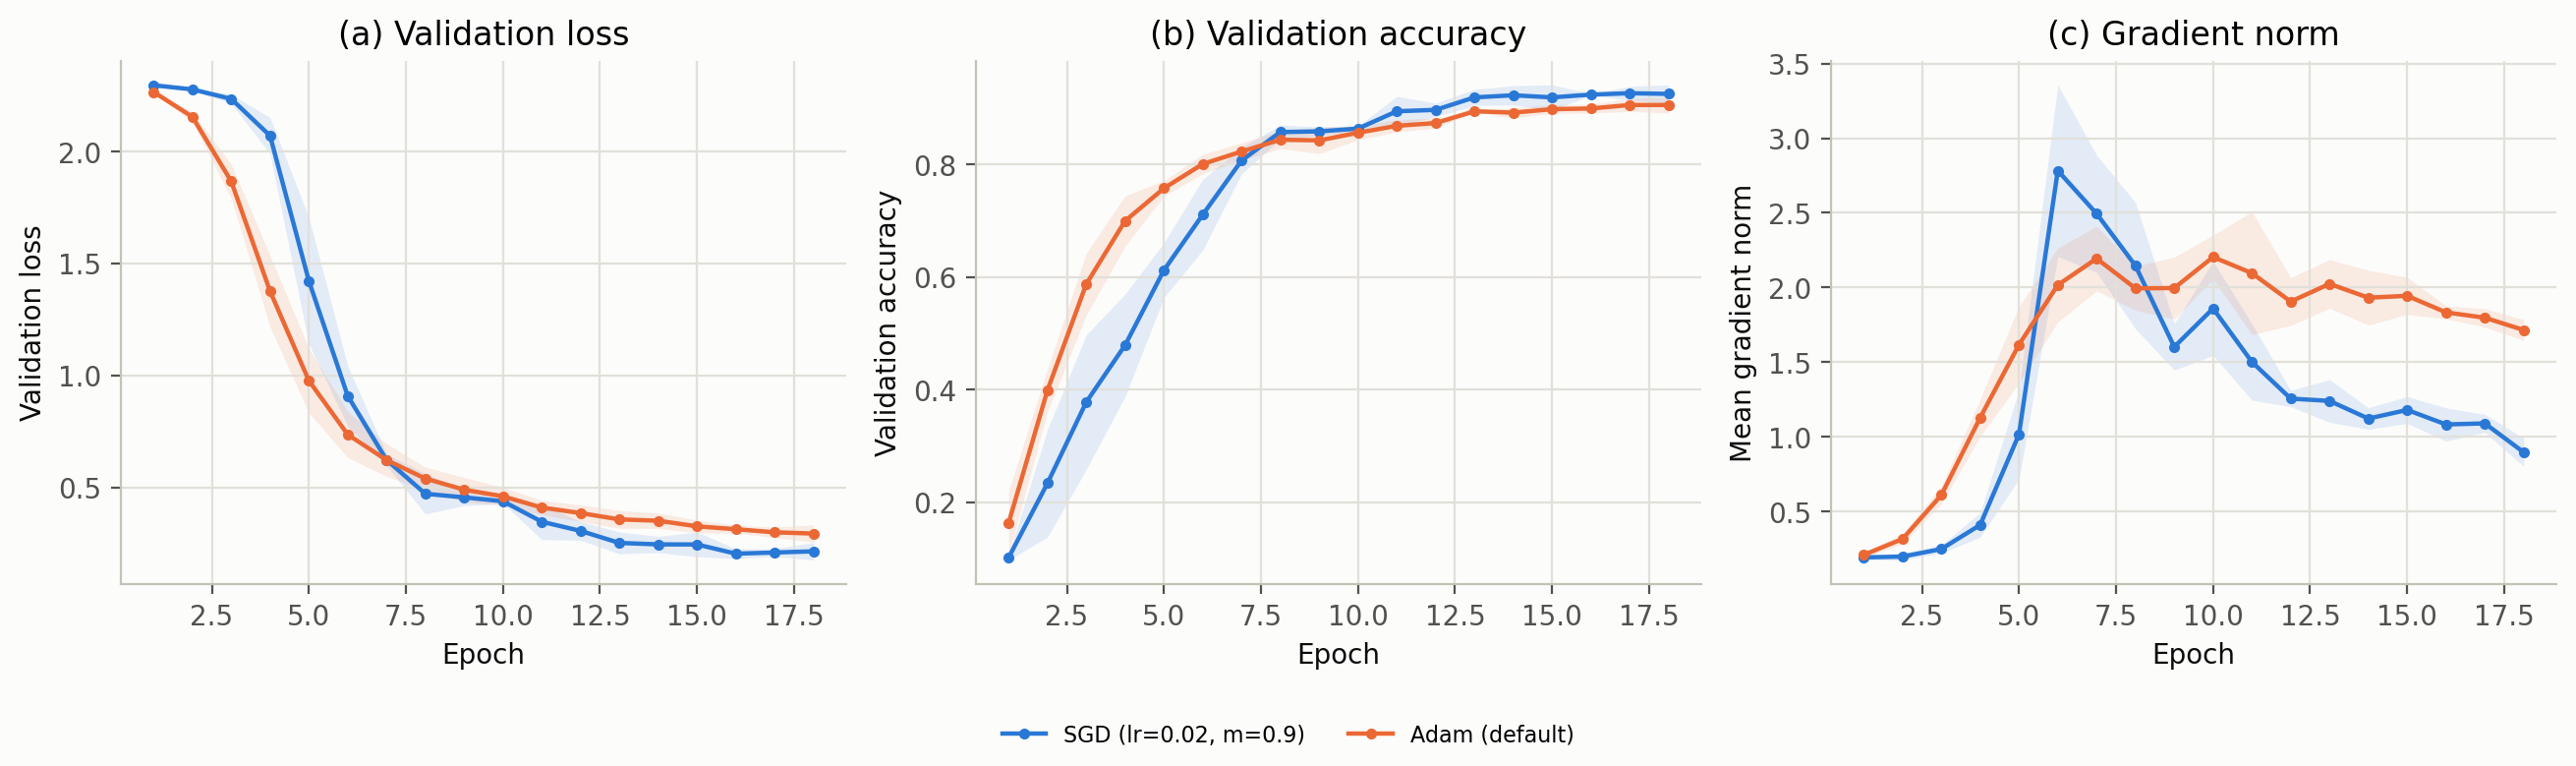

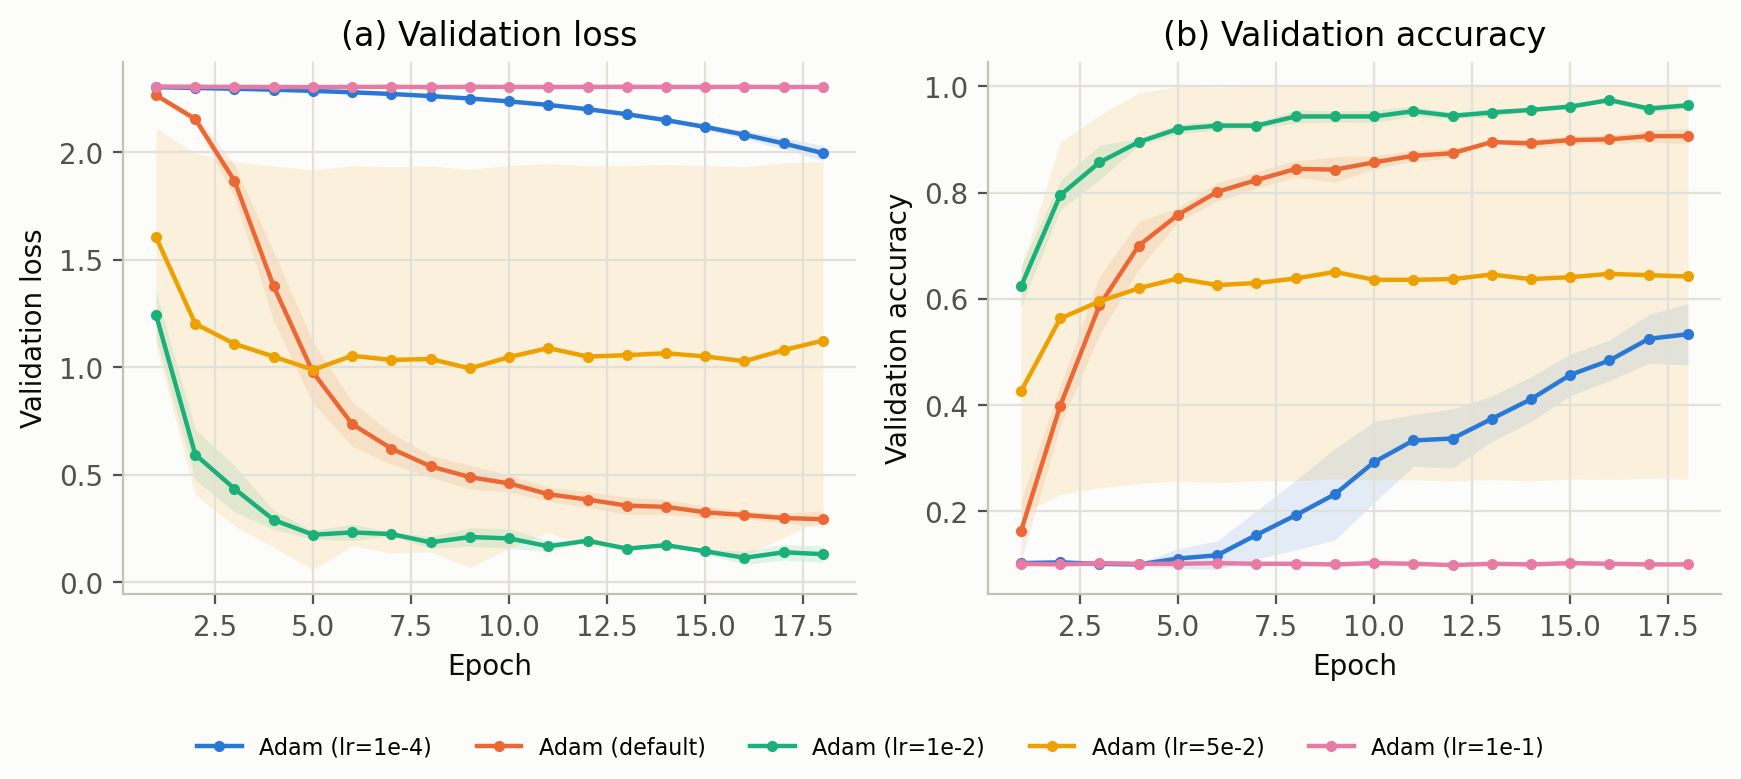

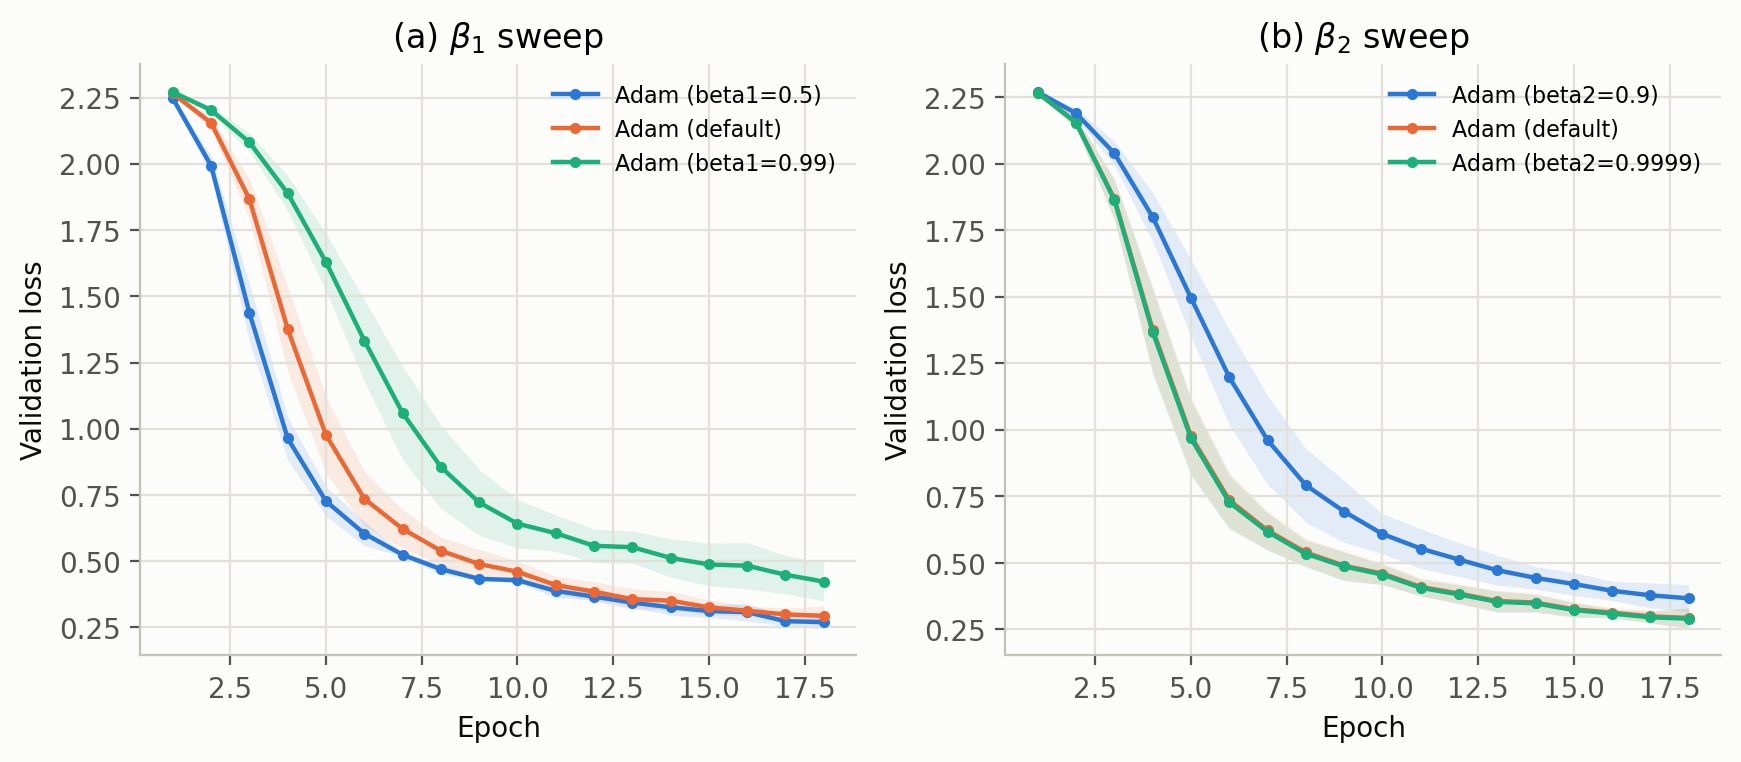

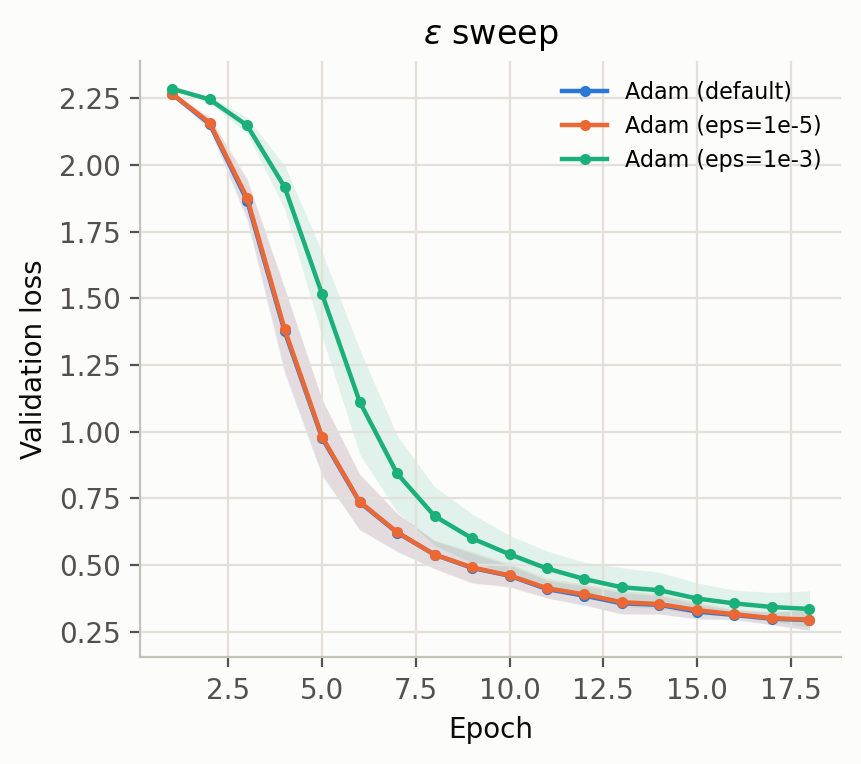

,组别,配置,有效种子数,测试损失,测试准确率,验证损失,验证准确率,梯度范数
0,baseline,"SGD (lr=0.02, m=0.9)",3,0.1130±0.0135,0.9630±0.0060,0.2142±0.0394,0.9259±0.0160,0.8980±0.0951
1,baseline,Adam (default),3,0.1762±0.0129,0.9481±0.0030,0.2935±0.0382,0.9062±0.0140,1.7160±0.0696
2,lr,Adam (lr=1e-4),3,1.9768±0.0385,0.5691±0.0501,1.9961±0.0351,0.5333±0.0577,0.6594±0.0589
3,lr,Adam (lr=1e-2),3,0.0537±0.0182,0.9840±0.0017,0.1309±0.0378,0.9642±0.0063,0.2235±0.0842
4,lr,Adam (lr=5e-2),3,0.9527±0.9569,0.6642±0.3990,1.1238±0.8338,0.6420±0.3810,0.6396±0.3697
5,lr,Adam (lr=1e-1),3,2.3035±0.0006,0.1025±0.0017,2.3035±0.0004,0.1000±0.0000,0.1272±0.0047
6,beta1,Adam (beta1=0.5),3,0.1661±0.0208,0.9494±0.0076,0.2701±0.0245,0.9099±0.0143,1.6552±0.0517
7,beta1,Adam (beta1=0.99),3,0.2400±0.0291,0.9136±0.0167,0.4229±0.0721,0.8827±0.0076,2.8074±0.2395
8,beta2,Adam (beta2=0.9),3,0.2402±0.0089,0.9235±0.0076,0.3670±0.0506,0.8877±0.0092,2.1408±0.1425
9,beta2,Adam (beta2=0.9999),3,0.1739±0.0135,0.9469±0.0017,0.2905±0.0372,0.9074±0.0157,1.7016±0.0708


In [6]:
cnn_table = cnn_experiments()
for name in ["Adam与SGD基线对比.png", "学习率敏感性.png", "矩估计系数敏感性.png", "稳定项敏感性.png"]:
    display(Image(filename=str(FIG_DIR / name)))
display(cnn_table)

# 6 结论

二次型实验表明，Adam 的归一化更新对目标整体缩放近似不变：目标放大 $10^{3}$ 倍后其收敛曲线与原来重合，而 GD 因等效步长放大而发散；GD 的稳定域与条件数结论则作为理解 CNN 学习率敏感性的背景。CNN 实验表明，Adam 对学习率最敏感，$\beta_1$ 过大、$\beta_2$ 过小或 $\epsilon$ 过大都会降低性能；动量 SGD 的最终泛化略优于默认 Adam，而 $\alpha=10^{-2}$ 的 Adam 取得最佳测试准确率。两部分共同说明：数值分析中的稳定性、条件数与尺度分析，可以为理解和调优 CNN 训练提供直接依据。